In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_json('processed-execution-dataset.json')

In [3]:
import json

def create_sets(df):
    X = []
    Y = []

    records = json.loads(df.to_json(orient='records'))

    for record in records:
        X.append({
            "code": record.get("actual_code"),
            "ip_variables": record.get("ip_variables"),
            "imports": record.get("imports")
        })
        Y.append({
            "memory_usage": record.get("memory_usage"),
            "disk_usage": record.get("disk_usage"),
            "execution_time": record.get("execution_time")
        })

    return X, Y, records[0].get("class_name", "")

In [4]:
from sklearn.model_selection import train_test_split

x_train, y_train, x_val, y_val = [], [], [], []

for cluster_id, group_df in df.groupby('cluster'):
    # if cluster_id == -1:
    #   continue

    train_df, val_df = train_test_split(group_df, test_size=0.15, random_state=42)

    xt_train, yt_train, _ = create_sets(train_df)
    xt_val, yt_val, _ = create_sets(val_df)

    x_train += xt_train
    y_train += yt_train
    x_val += xt_val
    y_val += yt_val

In [5]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
%pip install sentencepiece

In [ ]:
from transformers import AutoTokenizer, T5EncoderModel

model_name = "Salesforce/codet5-small"

In [9]:
class ExecutionDataset(Dataset):
    def __init__(self, model_name, X, Y, y_min, y_max):
        self.X = X
        self.Y = Y
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.y_min = y_min
        self.y_max = y_max

    def __len__(self):
        return len(self.X)

    def add_comments(self, code, variables, imports):
        for (k, v) in imports.items():
            code = code.replace(k, v)
            
        loc = code.split("\n")
        var_ids = list(variables.keys())
        used_vars = []

        for i, l in enumerate(loc):
            vars = []
            for k in list(variables.keys()):
                if k in l and k not in used_vars:
                    vars.append(k)
            if len(vars) > 0:
                comments = []
                for k in vars:
                    v = variables.get(k)
                    if v is not None:
                        comments.append(f"({k}, type: {v["id"]}, shape: {str(v["shape"]) if v["shape"] is not None else None}, is_sliced_values: {bool(v["sliced"])})")
                used_vars += vars
                loc[i] += f" # variables: {', '.join(comments)}"

        return "\n".join(loc)

    def format_variables(self, variables):
        var_info = ""
        for (k, v) in variables.items():
            if v is not None:
                var_info += f"{k}:\n"
                var_info += f"\ttype: {v["id"]}\n"
                var_info += f"\tshape: {str(v["shape"]) if v["shape"] is not None else None}\n"
                var_info += f"\tis_sliced_values: {bool(v["sliced"])}\n"
        return var_info

    def __getitem__(self, idx):
        inputs = self.X[idx]
        outputs = self.Y[idx]

        code = inputs["code"]
        variables = inputs["ip_variables"]
        imports = inputs["imports"]

        text = f"""
        <task> Predict peak memory usage from code (known variable data is provided and also in comments) </task>

        <code>
        {self.add_comments(code, variables, imports)}
        </code>

        <variables>
        {self.format_variables(variables)}
        </variables>
        """

        encoding = self.tokenizer(
            text,
            max_length=512,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        memory_value = np.log1p(float(outputs["memory_usage"]["peak_memory"]))
        norm_memory_value = (memory_value - self.y_min)/(self.y_max - self.y_min)

        return {
            "input_ids": encoding["input_ids"].squeeze(),
            "attention_mask": encoding["attention_mask"].squeeze(),
            "labels": torch.tensor(norm_memory_value, dtype=torch.float)
        }


In [10]:
def train(train_loader, model, criterion, optimizer):
    model.train()
    losses = []

    it_train = tqdm(enumerate(train_loader), total=len(train_loader), desc="Training ...", position = 0)
    for i, batch in it_train:
        input_ids, attention_mask, labels = batch["input_ids"].to(device), batch["attention_mask"].to(device), batch["labels"].to(device)
        optimizer.zero_grad()

        outputs = model(input_ids, attention_mask)
        
        loss = criterion(outputs, labels)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss)
        it_train.set_description(f'loss: {loss:.3f}')
    return torch.stack(losses).mean().item()

In [11]:
def evaluate(val_loader, model, criterion):
    model.eval()
    losses = []
    preds, golds = [], []

    it_val = tqdm(enumerate(val_loader), total=len(val_loader), desc="Validating ...", position = 0)
    with torch.set_grad_enabled(False):
      for i, batch in it_val:
        input_ids, attention_mask, labels = batch["input_ids"].to(device), batch["attention_mask"].to(device), batch["labels"].to(device)

        outputs = model(input_ids, attention_mask)

        loss = criterion(outputs, labels)
        losses.append(loss.item())
        
        preds.extend(outputs.cpu().numpy())
        golds.extend(labels.cpu().numpy())
        
    preds = np.expm1(np.array(preds))
    golds = np.expm1(np.array(golds))

    rmse = np.sqrt(((preds - golds) ** 2).mean())
    val_loss = np.mean(losses)
    print('RMSE: {0:.4f}'.format(rmse))
    print('Avg loss: {}'.format(val_loss))
    
    return rmse, val_loss

In [12]:
class Model(nn.Module):
    def __init__(self, model_name, freeze_layers=6):
        super().__init__()
        self.encoder = T5EncoderModel.from_pretrained(model_name)

        for name, param in self.encoder.named_parameters():
            if any(name.startswith(f"encoder.block.{i}") for i in range(freeze_layers)):
                param.requires_grad = False

        hidden_size = self.encoder.config.hidden_size
        self.regression_head = nn.Sequential(
            nn.Dropout(0.1),
            nn.Linear(hidden_size, 1)
        )
    
    def forward(self, input_ids, attention_mask):
        enc = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1)
        pooled = (enc * mask).sum(1) / mask.sum(1)
        out = self.regression_head(pooled)
        return out.squeeze(-1)

In [13]:
train_memory = np.array([float(y["memory_usage"]["peak_memory"]) for y in y_train])
train_log = np.log1p(train_memory)

y_min = train_log.min()
y_max = train_log.max()

train_ds = ExecutionDataset(model_name, x_train, y_train, y_min=y_min, y_max=y_max)
val_ds = ExecutionDataset(model_name, x_val, y_val, y_min=y_min, y_max=y_max)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=2, shuffle=False)

In [14]:
num_epochs = 20
test_interval = 1

model = Model(model_name)
model = model.to(device)
print(model)

learn_rate = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=learn_rate)
lr_scheduler =  torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

criterion = nn.MSELoss()

epochs_list = []
train_losses = []
train_rmse_list = []
val_losses = []
val_rmse_list = []

for epoch in tqdm(range(num_epochs), total=num_epochs, desc="Training ...", position=1):
    train_loss = train(train_loader, model, criterion, optimizer)
    # lr_scheduler.step()

    print(f'Loss for Training on epoch {str(epoch)} is {str(train_loss)} \n')

    if(epoch%test_interval==0 or epoch==1 or epoch==num_epochs-1):
        print('Evaluating Network')

        epochs_list.append(epoch)

        train_rmse, train_loss = evaluate(train_loader, model, criterion)
        train_losses.append(train_loss)
        train_rmse_list.append(train_rmse)

        print(f'Training RMSE on epoch {str(epoch)} is {str(train_rmse)} \n')

        val_rmse, val_loss = evaluate(val_loader, model, criterion)
        val_losses.append(val_loss)
        val_rmse_list.append(val_rmse)

        print(f'Val RMSE on epoch {str(epoch)} is {str(val_rmse)} \n')


Model(
  (encoder): T5EncoderModel(
    (shared): Embedding(32100, 512)
    (encoder): T5Stack(
      (embed_tokens): Embedding(32100, 512)
      (block): ModuleList(
        (0): T5Block(
          (layer): ModuleList(
            (0): T5LayerSelfAttention(
              (SelfAttention): T5Attention(
                (q): Linear(in_features=512, out_features=512, bias=False)
                (k): Linear(in_features=512, out_features=512, bias=False)
                (v): Linear(in_features=512, out_features=512, bias=False)
                (o): Linear(in_features=512, out_features=512, bias=False)
                (relative_attention_bias): Embedding(32, 8)
              )
              (layer_norm): T5LayerNorm()
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (1): T5LayerFF(
              (DenseReluDense): T5DenseActDense(
                (wi): Linear(in_features=512, out_features=2048, bias=False)
                (wo): Linear(in_features=2048, out_featu


loss: 0.004: 100%|██████████| 6113/6113 [01:50<00:00, 55.50it/s]


Loss for Training on epoch 0 is 0.015971502289175987 

Evaluating Network


Validating ...: 100%|██████████| 6113/6113 [00:46<00:00, 132.33it/s]


RMSE: 0.1481
Avg loss: 0.00986507537354614
Training RMSE on epoch 0 is 0.14814581 



Validating ...: 100%|██████████| 1133/1133 [00:08<00:00, 132.16it/s]

Training ...:   5%|▌         | 1/20 [02:45<52:33, 165.98s/it]

... (111 outputs left out)

Validating ...: 100%|██████████| 6113/6113 [00:46<00:00, 131.94it/s]


RMSE: 0.0848
Avg loss: 0.0034527653978112392
Training RMSE on epoch 19 is 0.0848481 



Validating ...: 100%|██████████| 1133/1133 [00:08<00:00, 131.23it/s]

Training ...: 100%|██████████| 20/20 [57:12<00:00, 171.64s/it]

RMSE: 0.1050
Avg loss: 0.005316389945586441
Val RMSE on epoch 19 is 0.10500727 



In [15]:
import matplotlib.pyplot as plt

def plot_results(epochs, train, val, metric_name="Loss"):
    plt.plot(epochs, train, label="train")
    plt.plot(epochs, val, label="val")
    plt.title(metric_name + " Plot")
    plt.ylabel(metric_name)
    plt.xlabel("Epoch")
    plt.legend()
    plt.show()

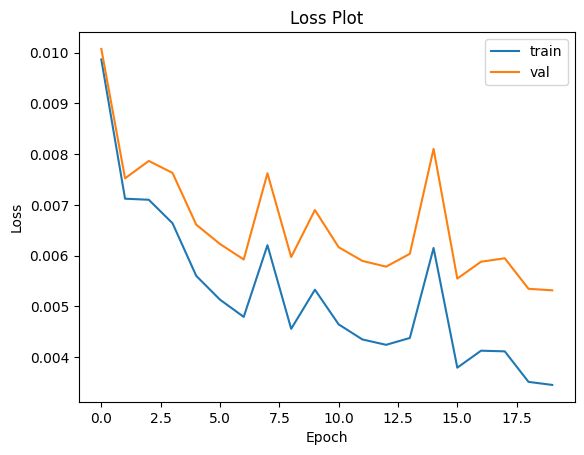

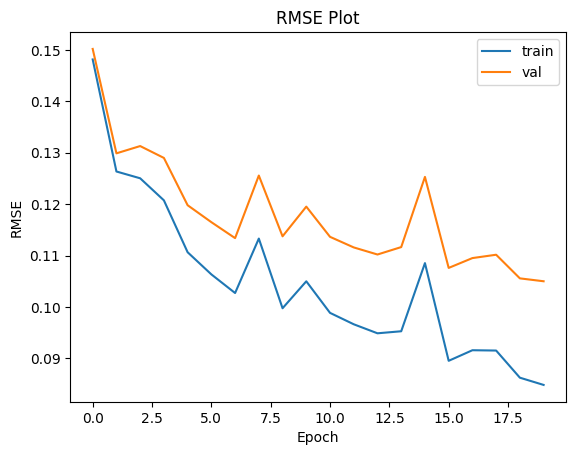

In [16]:
plot_results(epochs_list, train_losses, val_losses, "Loss")
plot_results(epochs_list, train_rmse_list, val_rmse_list, "RMSE")